In [97]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score

In [2]:
main_df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Operations - Documents\Engineering\Disposal Wells\Workover Analysis\Derived All Data.xlsx")
print(main_df.columns)

Index(['Unnamed: 0.1', 'Unnamed: 0', 'Name', 'Year-Month', 'Hours',
       'Water Total', 'PSI', 'Revenue', 'Metered DM', 'Power Factor',
       'Billed DM', 'Billing KWH', 'Fuel Rate', 'Electrical Bill',
       'Workover Info', 'Workover Cost', 'Pump Model', 'Pump Number',
       'Plunger Size', 'Install Date', 'Maintenance Cost',
       'Maintenance Comments', 'Workover Count', 'Disposal Rate',
       'KWH per Barrel', 'Cost per KWH', 'Electrical Cost per Barrel',
       'Maintenance Cost per Barrel', 'Workover Cost per Barrel',
       'Revenue per Barrel', 'Income per Barrel', 'Income', 'Total Cost',
       '6 Month Avg KWH', '6 Month Avg Revenue', '6 Month Avg Income',
       '6 Month Avg Total Cost', '6 Month Avg Electrical Cost',
       '6 Month Avg Maintenance Cost', '6 Month Avg Workover Cost',
       '6 Month Avg KWH per Barrel Weighted', '6 Month Avg Cost per KWH',
       '6 Month Avg Electrical Cost per Barrel',
       '6 Month Avg Maintenance Cost per Barrel',
       '6 Mon

In [3]:

#Replacing the Nan pump model values with valid entries
filt_df = main_df[["Name", "Pump Model"]]
na_filt = filt_df["Pump Model"].isna()
wells_and_pumps = filt_df[~na_filt]
wells = main_df["Name"].unique()

pumps = main_df["Pump Model"].unique()

pump_mapping = (
    wells_and_pumps
    .drop_duplicates(subset=["Name"])
    .set_index("Name")["Pump Model"]
)

main_df["Pump Model"] = main_df["Pump Model"].fillna(
    main_df["Name"].map(pump_mapping)
)

# which wells in pump_mapping (wells that are mapped to a pump), do not have
# a pump model associated with them?
all_well_set = set(wells)
pump_well_set = set(pump_mapping.index)



In [4]:
main_df = main_df.dropna(subset=["PSI", "Water Total", "Metered DM", "Pump Model"])

#Creating new pump model column
main_df["Pump Model ID"] = pd.factorize(main_df["Pump Model"])[0]

main_df[["Pump Model ID", "Pump Model"]]

,Pump Model ID,Pump Model
108,0,M520A C-CT-ARZ
109,0,M520A C-CT-ARZ
110,0,M520A C-CT-ARZ
111,0,M520A C-CT-ARZ
112,0,M520A C-CT-ARZ
...,...,...
9283,1,A546
9284,1,A546
9285,1,A546
9286,1,A546


In [87]:
features = ["PSI", "Water Total", "Metered DM"]
X_df = main_df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_df)

In [88]:
#establishing the kmeans object as a variable 
#y predicted is an array of the cluster groups
km = KMeans(n_clusters=6, random_state=42)
main_df["Cluster Labels"] = km.fit_predict(X_scaled)

# Extract the unscaled centroids for plotting
# If you plot scaled centroids on unscaled data, they won't align. 
# We inverse-transform them back to their original PSI/Water/DM units:
centroids = scaler.inverse_transform(km.cluster_centers_)

In [89]:
for i, coord in enumerate(centroids):
    print(f"Centroid {i}: PSI={coord[0]:.2f}, Water={coord[1]:.2f}, DM={coord[2]:.2f}")


Centroid 0: PSI=870.39, Water=100171.37, DM=187.23
Centroid 1: PSI=781.32, Water=416382.47, DM=170.46
Centroid 2: PSI=2.23, Water=4299.18, DM=51.87
Centroid 3: PSI=730.61, Water=121114.60, DM=72.90
Centroid 4: PSI=784.66, Water=550847.46, DM=248.37
Centroid 5: PSI=685.15, Water=552963.71, DM=650.86


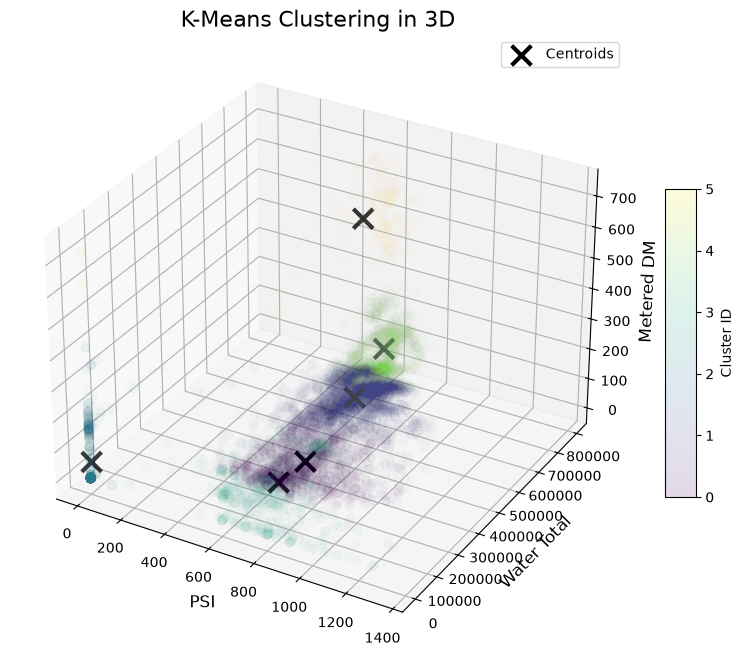

In [90]:


fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    main_df["PSI"],
    main_df["Water Total"], 
    main_df["Metered DM"],
    c=main_df["Cluster Labels"],
    cmap="viridis",
    s=40,
    alpha=0.15
)


ax.scatter(
    centroids[:, 0],
    centroids[:, 1 ],
    centroids[:, 2],
    c="black",
    marker="x",
    s=200,
    linewidth=3,
    label="Centroids",
    zorder=11
)

ax.set_title('K-Means Clustering in 3D', fontsize=16)
ax.set_xlabel('PSI', fontsize=12)
ax.set_ylabel('Water Total', fontsize=12)
ax.set_zlabel('Metered DM', fontsize=12)

# Add a color bar for clusters and a legend for centroids
fig.colorbar(scatter, ax=ax, label='Cluster ID', shrink=0.5, aspect=10)
ax.legend()

plt.show()

In [93]:
pump_id = main_df["Pump Model ID"].to_numpy()
cluster_labels = main_df["Cluster Labels"].to_numpy()
cluster_labels

array([4, 4, 4, ..., 1, 1, 1], shape=(8316,), dtype=int32)

In [94]:
#adjusted rand score calculated to measure the two data clusterings
adjusted_rand_score(pump_id, cluster_labels)

0.30984310472517196

In [100]:
main_df[["Pump Model", "Pump Model ID", "Cluster Labels"]]

,Pump Model,Pump Model ID,Cluster Labels
108,M520A C-CT-ARZ,2,4
109,M520A C-CT-ARZ,2,4
110,M520A C-CT-ARZ,2,4
111,M520A C-CT-ARZ,2,4
112,M520A C-CT-ARZ,2,4
...,...,...,...
9283,A546,5,1
9284,A546,5,1
9285,A546,5,1
9286,A546,5,1
